In [3]:

from google.colab import files

uploaded = files.upload()

Saving Global_Warming_Cleaned.zip to Global_Warming_Cleaned.zip


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Week 3 cleaned dataset
df = pd.read_csv("Global_Warming_Cleaned.zip")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.head())


Dataset shape: (100000, 26)
Total missing values: 0
Duplicate rows: 0


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.163537,8.876061e+08,1.627978e+08,54.872178,6.139887e+12,76.710013,8.317626e+06,8.111839,...,82.691409,2.285351,4.060975,150.285539,90.073356,8.025470,39.163860,1480.164332,78.870012,20.825292
1,Country_180,1950,-0.432122,4.497517e+08,4.281359e+08,84.051006,2.601447e+12,68.450021,6.206540e+06,42.025915,...,59.322883,17.411668,85.300604,27.305922,88.289837,8.021719,28.252554,1482.730048,32.600905,28.720587
2,Country_93,2014,0.444954,4.579080e+08,4.926732e+08,72.295357,5.192677e+12,36.725699,1.056885e+06,20.953840,...,94.982931,12.039703,83.804880,216.911429,86.936256,7.647408,61.548382,706.918809,37.671300,15.014084
3,Country_15,2020,-1.171616,5.049503e+08,1.252169e+09,17.259684,8.252128e+12,77.547901,1.986813e+06,45.599595,...,62.064250,2.853957,47.014265,35.869182,44.904331,7.569353,82.423750,2616.238324,86.581725,-1.277086
4,Country_107,1964,-0.564038,6.898891e+08,2.932960e+08,44.438605,8.560746e+12,10.019576,3.313252e+06,7.652150,...,84.431279,19.801173,89.379613,284.263093,8.102916,8.015415,29.964450,4975.683780,20.618406,2.861989


In [7]:

# Select numerical columns, excluding Year from transformation analysis
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [col for col in numeric_cols if col != "Year"]

# Calculate descriptive statistics
stats = df[feature_cols].describe().T

stats["skewness"] = df[feature_cols].skew()
stats["kurtosis"] = df[feature_cols].kurtosis()

stats = stats[
    ["mean", "std", "min", "25%", "50%", "75%", "max",
         "skewness", "kurtosis"]
         ]

display(stats.round(3))


,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Temperature_Anomaly,3.000000e-03,1.155000e+00,-2.000000e+00,-9.990000e-01,4.000000e-03,9.980000e-01,2.000000e+00,-0.001,-1.200
CO2_Emissions,5.007007e+08,2.887388e+08,1.022271e+05,2.504223e+08,5.006769e+08,7.506318e+08,9.999793e+08,-0.002,-1.199
Population,7.501973e+08,4.328709e+08,1.013054e+06,3.762545e+08,7.499212e+08,1.125222e+09,1.499992e+09,0.001,-1.200
Forest_Area,5.001200e+01,2.880600e+01,0.000000e+00,2.496000e+01,5.014100e+01,7.489800e+01,1.000000e+02,-0.001,-1.197
GDP,4.995923e+12,2.883117e+12,1.524737e+08,2.507503e+12,4.985849e+12,7.489082e+12,9.999894e+12,0.006,-1.194
Renewable_Energy_Usage,5.011600e+01,2.884100e+01,5.000000e-03,2.530200e+01,5.001200e+01,7.509600e+01,9.999900e+01,-0.000,-1.197
Methane_Emissions,5.003713e+06,2.887606e+06,1.133254e+03,2.501312e+06,4.997724e+06,7.507855e+06,9.999928e+06,-0.000,-1.203
Sea_Level_Rise,2.256800e+01,1.590800e+01,-5.000000e+00,8.739000e+00,2.272800e+01,3.633300e+01,4.999800e+01,-0.010,-1.205
Arctic_Ice_Extent,8.004000e+00,4.039000e+00,1.000000e+00,4.505000e+00,7.999000e+00,1.150000e+01,1.500000e+01,0.004,-1.198
Urbanization,4.991900e+01,2.884600e+01,0.000000e+00,2.499000e+01,4.978200e+01,7.486000e+01,1.000000e+02,0.004,-1.197


Dataset shape: (100000, 26)
Feature columns: 24
Testing feature: Temperature_Anomaly


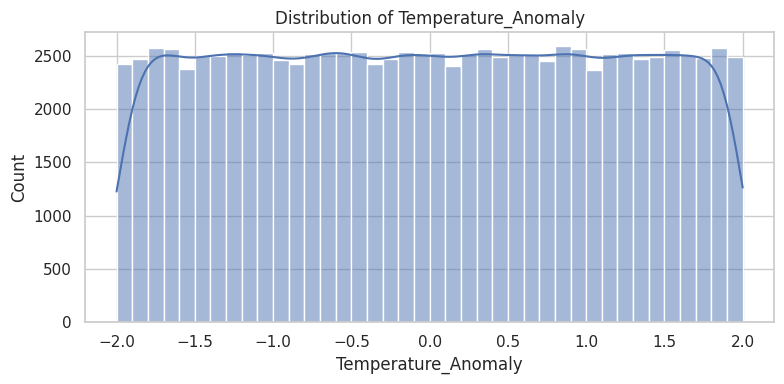

In [10]:

plt.close("all")

print("Dataset shape:", df.shape)
print("Feature columns:", len(feature_cols))
print("Testing feature:", feature_cols[0])

fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    df[feature_cols[0]].dropna(),
        bins=40,
            kde=True,
                ax=ax
                )

ax.set_title(f"Distribution of {feature_cols[0]}")
plt.tight_layout()
plt.show()
plt.close(fig)


In [11]:

from sklearn.preprocessing import StandardScaler

# Create a separate copy for feature engineering
df_scaled = df.copy()

# Numerical features to scale; exclude Year
numeric_features = df.select_dtypes(include=np.number).columns.tolist()
numeric_features.remove("Year")

# Apply standard scaling
scaler = StandardScaler()
df_scaled[numeric_features] = scaler.fit_transform(
    df[numeric_features]
    )

print("Scaling completed!")
print("Original dataset shape:", df.shape)
print("Transformed dataset shape:", df_scaled.shape)

display(df_scaled.head())


Scaling completed!
Original dataset shape: (100000, 26)
Transformed dataset shape: (100000, 26)


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.010057,1.339991,-1.356992,0.168706,0.396782,0.922091,1.147639,-0.908733,...,1.131216,-1.334617,-1.592458,0.007597,1.403033,0.087711,-0.378698,-0.761490,1.011754,0.405460
1,Country_180,1950,-0.376563,-0.176455,-0.744016,1.181644,-0.830521,0.635697,0.416550,1.223143,...,0.322356,1.292495,1.217348,-1.412504,1.340615,0.074585,-0.760084,-0.759660,-0.609046,0.958128
2,Country_93,2014,0.383091,-0.148206,-0.594924,0.773548,0.068244,-0.464263,-1.366823,-0.101471,...,1.556665,0.359502,1.165616,0.776956,1.293243,-1.235330,0.403715,-1.312921,-0.431431,-0.001323
3,Country_15,2020,-1.017054,0.014718,1.159639,-1.137005,1.129410,0.951143,-1.044781,1.447789,...,0.417244,-1.235863,-0.106848,-1.313620,-0.177755,-1.508485,1.133378,0.048688,1.281894,-1.141700
4,Country_107,1964,-0.490818,0.655227,-1.055519,-0.193494,1.236454,-1.390229,-0.585422,-0.937630,...,1.191438,1.707501,1.358428,1.554695,-1.465700,0.052522,-0.700248,1.731299,-1.028791,-0.851966


In [12]:

verification = pd.DataFrame({
    "Original Mean": df[numeric_features].mean(),
        "Scaled Mean": df_scaled[numeric_features].mean(),
            "Original Std": df[numeric_features].std(),
                "Scaled Std": df_scaled[numeric_features].std()
                })

display(verification.round(4))


,Original Mean,Scaled Mean,Original Std,Scaled Std
Temperature_Anomaly,2.600000e-03,-0.0,1.154600e+00,1.0
CO2_Emissions,5.007007e+08,0.0,2.887388e+08,1.0
Population,7.501973e+08,-0.0,4.328709e+08,1.0
Forest_Area,5.001240e+01,0.0,2.880630e+01,1.0
GDP,4.995923e+12,0.0,2.883117e+12,1.0
Renewable_Energy_Usage,5.011570e+01,-0.0,2.884150e+01,1.0
Methane_Emissions,5.003713e+06,-0.0,2.887606e+06,1.0
Sea_Level_Rise,2.256800e+01,0.0,1.590820e+01,1.0
Arctic_Ice_Extent,8.003900e+00,-0.0,4.039100e+00,1.0
Urbanization,4.991880e+01,-0.0,2.884600e+01,1.0


In [13]:

from sklearn.preprocessing import MinMaxScaler

# Create a separate copy
df_minmax = df.copy()

# Apply MinMax scaling to numerical features, excluding Year
minmax_scaler = MinMaxScaler()

df_minmax[numeric_features] = minmax_scaler.fit_transform(
    df[numeric_features]
    )

comparison = pd.DataFrame({
        "Original Min": df[numeric_features].min(),
            "Original Max": df[numeric_features].max(),
                "StandardScaler Min": df_scaled[numeric_features].min(),
                    "StandardScaler Max": df_scaled[numeric_features].max(),
                        "MinMaxScaler Min": df_minmax[numeric_features].min(),
                            "MinMaxScaler Max": df_minmax[numeric_features].max()
                            })

display(comparison.round(3))


,Original Min,Original Max,StandardScaler Min,StandardScaler Max,MinMaxScaler Min,MinMaxScaler Max
Temperature_Anomaly,-2.000000e+00,2.000000e+00,-1.735,1.730,0.0,1.0
CO2_Emissions,1.022271e+05,9.999793e+08,-1.734,1.729,0.0,1.0
Population,1.013054e+06,1.499992e+09,-1.731,1.732,0.0,1.0
Forest_Area,0.000000e+00,1.000000e+02,-1.736,1.735,0.0,1.0
GDP,1.524737e+08,9.999894e+12,-1.733,1.736,0.0,1.0
Renewable_Energy_Usage,5.000000e-03,9.999900e+01,-1.737,1.730,0.0,1.0
Methane_Emissions,1.133254e+03,9.999928e+06,-1.732,1.730,0.0,1.0
Sea_Level_Rise,-5.000000e+00,4.999800e+01,-1.733,1.724,0.0,1.0
Arctic_Ice_Extent,1.000000e+00,1.500000e+01,-1.734,1.732,0.0,1.0
Urbanization,0.000000e+00,1.000000e+02,-1.731,1.736,0.0,1.0


In [14]:

# One-hot encode Country
df_encoded = pd.get_dummies(
    df_scaled,
        columns=["Country"],
            dtype=int
            )

print("Original columns:", df.shape[1])
print("Columns after encoding:", df_encoded.shape[1])
print("\nSample encoded columns:")
display(df_encoded.filter(regex="^Country_").head())


Original columns: 26
Columns after encoding: 220

Sample encoded columns:


,Country_Country_1,Country_Country_10,Country_Country_100,Country_Country_101,Country_Country_102,Country_Country_103,Country_Country_104,Country_Country_105,Country_Country_106,Country_Country_107,...,Country_Country_90,Country_Country_91,Country_Country_92,Country_Country_93,Country_Country_94,Country_Country_95,Country_Country_96,Country_Country_97,Country_Country_98,Country_Country_99
0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [15]:

# Save the main transformed dataset
df_scaled.to_csv(
    "Week6_StandardScaled_Dataset.csv",
        index=False
        )

        # Save the MinMax-scaled dataset
df_minmax.to_csv(
            "Week6_MinMaxScaled_Dataset.csv",
                index=False
                )

                # Save the one-hot encoded dataset
df_encoded.to_csv(
                    "Week6_Encoded_Dataset.csv",
                        index=False
                        )

                        # Save statistical analysis
stats.to_csv("Week6_Descriptive_Statistics.csv")

print("Week 6 files saved successfully:")
print("- Week6_StandardScaled_Dataset.csv")
print("- Week6_MinMaxScaled_Dataset.csv")
print("- Week6_Encoded_Dataset.csv")
print("- Week6_Descriptive_Statistics.csv")


Week 6 files saved successfully:
- Week6_StandardScaled_Dataset.csv
- Week6_MinMaxScaled_Dataset.csv
- Week6_Encoded_Dataset.csv
- Week6_Descriptive_Statistics.csv


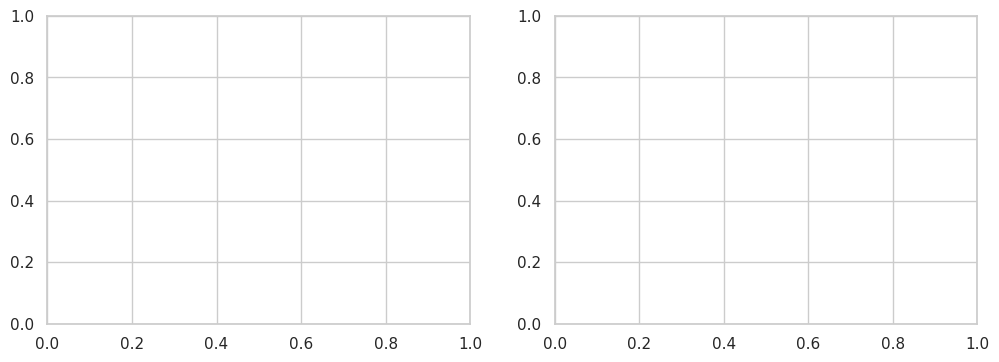

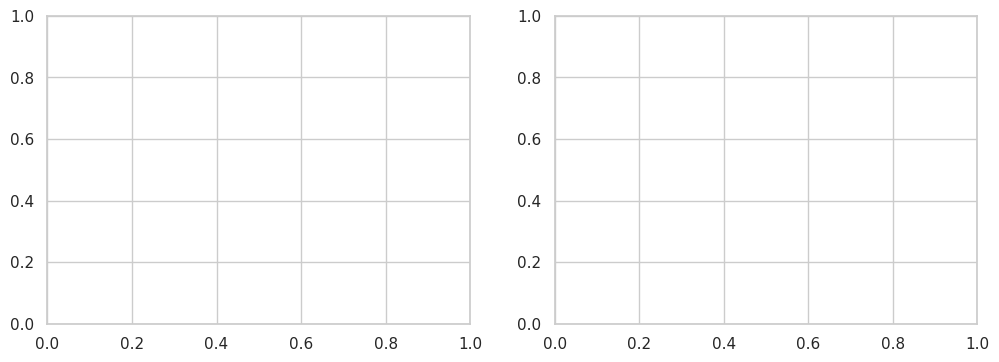

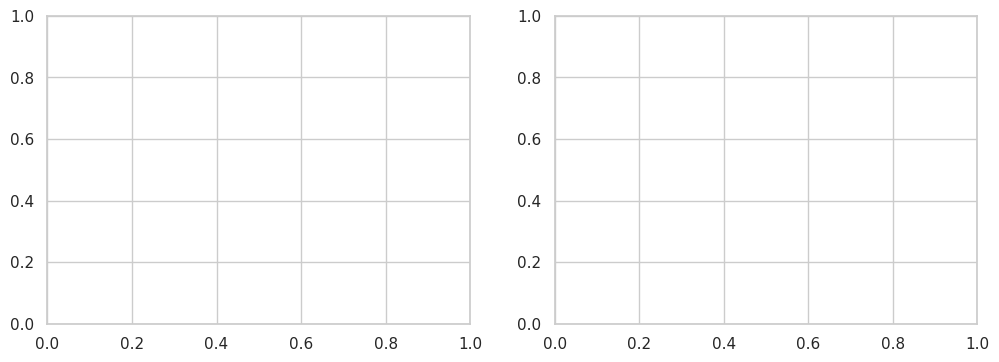

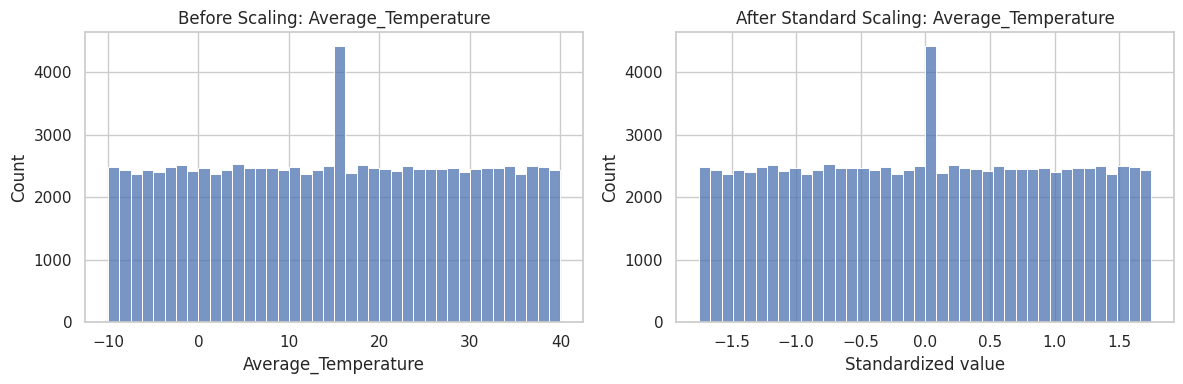

In [16]:

features_to_compare = [
    "CO2_Emissions",
    "GDP",
    "Temperature_Anomaly",
    "Average_Temperature"
]

for col in features_to_compare:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col], bins=40, ax=axes[0])
    axes[0].set_title(f"Before Scaling: {col}")
    axes[0].set_xlabel(col)

    sns.histplot(df_scaled[col], bins=40, ax=axes[1])
    axes[1].set_title(f"After Standard Scaling: {col}")
    axes[1].set_xlabel("Standardized value")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [17]:

from google.colab import files

files.download("Week6_StandardScaled_Dataset.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>